# Imports and Setup

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from PIL import Image
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

print(f"TensorFlow {tf.__version__}")

# GPU setup
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f" GPU: {gpus[0].name}")
else:
    print(" No GPU found!")

tf.keras.mixed_precision.set_global_policy('float32')

I0000 00:00:1785506784.604811  509388 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1785506786.102117  509388 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0
 GPU: /physical_device:GPU:0


# Load Dataset

In [2]:
DATASET_PATH = 'archive/img_align_celeba/img_align_celeba'

IMAGE_SIZE = 64
BATCH_SIZE = 128

print(f"Configuration: {IMAGE_SIZE}x{IMAGE_SIZE}, batch={BATCH_SIZE}")


def create_face_dataset(root_dir, image_size=64, batch_size=8):
    """Load face images"""
    root_path = Path(root_dir)
    
    # Find images
    image_files = []
    for ext in ['*.jpg', '*.jpeg', '*.png']:
        image_files.extend(list(root_path.glob(f'**/{ext}')))
    
    if len(image_files) == 0:
        raise FileNotFoundError(f"No images in {root_dir}")
    
    print(f" Found {len(image_files)} images")
    file_paths = [str(f) for f in image_files]
    
    def load_image(path):
        try:
            # Read file
            img = tf.io.read_file(path)
            
            # Decode with 3 channels explicitly
            img = tf.io.decode_jpeg(img, channels=3)  # Force 3 channels!
            
            # Convert to float and resize
            img = tf.image.convert_image_dtype(img, tf.float32)
            img = tf.image.resize(img, [image_size, image_size])
            
            # Random horizontal flip
            if tf.random.uniform([]) > 0.5:
                img = tf.image.flip_left_right(img)
            
            
            # Random brightness
            img = tf.image.random_brightness(img, max_delta=0.2)
            
            # Random contrast
            img = tf.image.random_contrast(img, lower=0.8, upper=1.2)
            
            # Random saturation
            img = tf.image.random_saturation(img, lower=0.7, upper=1.3)
            
            # Normalize to [-1, 1]
            img = (img - 0.5) * 2.0
            
            # Ensure shape is [H, W, 3]
            img = tf.ensure_shape(img, [image_size, image_size, 3])
            
            return img
        except Exception as e:
            # Return black RGB image on error
            return tf.zeros([image_size, image_size, 3])
    
    # Build pipeline
    ds = tf.data.Dataset.from_tensor_slices(file_paths)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE, deterministic=False)
    ds = ds.shuffle(500)
    ds = ds.batch(batch_size, drop_remainder=True)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    
    return ds, len(image_files)

# Load dataset
try:
    train_dataset, num_images = create_face_dataset(DATASET_PATH, IMAGE_SIZE, BATCH_SIZE)
    print(f" Dataset ready: {num_images} images, ~{num_images//BATCH_SIZE} batches")
    
    # Verify shape and values
    for batch in train_dataset.take(1):
        print(f"   Batch shape: {batch.shape}")
        print(f"   Value range: [{tf.reduce_min(batch):.2f}, {tf.reduce_max(batch):.2f}]")
        print(f"   Channels: {batch.shape[-1]}")
        
except FileNotFoundError:
    print(f" Dataset not found at: {DATASET_PATH}")
    print("Creating dummy data for testing...")
    
    # Create colorful dummy data instead of random noise
    dummy_data = tf.random.uniform([200, IMAGE_SIZE, IMAGE_SIZE, 3], minval=-1, maxval=1)
    train_dataset = tf.data.Dataset.from_tensor_slices(dummy_data)
    train_dataset = train_dataset.batch(BATCH_SIZE, drop_remainder=True).prefetch(tf.data.AUTOTUNE)
    num_images = 200
    print(" Using dummy data")

Configuration: 64x64, batch=128
 Found 202599 images
 Dataset ready: 202599 images, ~1582 batches
   Batch shape: (128, 64, 64, 3)
   Value range: [-1.42, 1.50]
   Channels: 3



# Show Sample Images


Displaying sample images...
Image shape: (8, 64, 64, 3)
Value range: [0.00, 1.00]
Sample pixel (first image, top-left): [0.3815508  0.25405508 0.15339106]


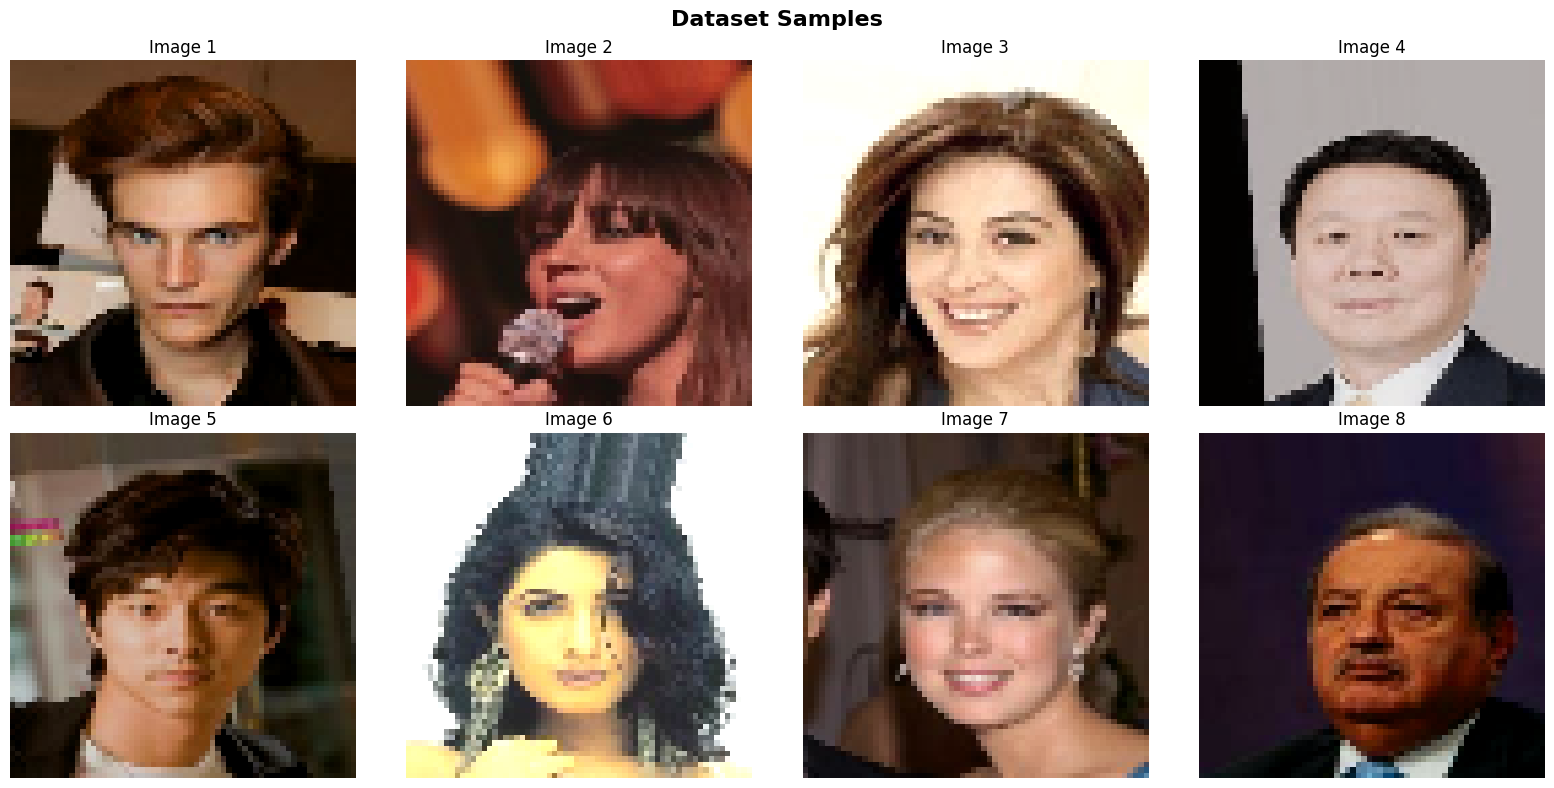

In [3]:
def denormalize(img):
    """Convert from [-1, 1] to [0, 1] range."""
    return tf.clip_by_value((img + 1.0) / 2.0, 0.0, 1.0)

def show_samples(dataset, n=8):
    """Display sample images with proper RGB colors."""
    for batch in dataset.take(1):
        # Get images and denormalize
        imgs = denormalize(batch[:n]).numpy()
        
        print(f"Image shape: {imgs.shape}")
        print(f"Value range: [{imgs.min():.2f}, {imgs.max():.2f}]")
        print(f"Sample pixel (first image, top-left): {imgs[0, 0, 0, :]}")
        
        # Display
        fig, axes = plt.subplots(2, 4, figsize=(16, 8))
        for i, ax in enumerate(axes.flat):
            if i < len(imgs):
                ax.imshow(imgs[i])
                ax.set_title(f'Image {i+1}')
            ax.axis('off')
        
        plt.suptitle('Dataset Samples', fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.show()
        break


# Display samples
print("="*50)
print("Displaying sample images...")
print("="*50)
show_samples(train_dataset)

# Custom Layers

In [4]:
@tf.keras.utils.register_keras_serializable(package='Custom')
class GroupNormalization(layers.Layer):
    """Group Normalization - stable for mixed precision."""
    def __init__(self, groups=8, epsilon=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.groups = groups
        self.epsilon = epsilon
    
    def build(self, input_shape):
        channels = input_shape[-1]
        self.gamma = self.add_weight(
            shape=(channels,), initializer="ones", trainable=True, name="gamma"
        )
        self.beta = self.add_weight(
            shape=(channels,), initializer="zeros", trainable=True, name="beta"
        )
        super().build(input_shape)
    
    def call(self, x, **kwargs):
        original_dtype = x.dtype
        x = tf.cast(x, tf.float32)
        gamma = tf.cast(self.gamma, tf.float32)
        beta = tf.cast(self.beta, tf.float32)
        
        B, H, W, C = tf.unstack(tf.shape(x))
        x = tf.reshape(x, [B, H, W, self.groups, C // self.groups])
        mean, var = tf.nn.moments(x, [1, 2, 4], keepdims=True)
        x = (x - mean) / tf.sqrt(var + self.epsilon)
        x = tf.reshape(x, [B, H, W, C])
        x = gamma * x + beta
        return tf.cast(x, original_dtype)
    
    def get_config(self):
        config = super().get_config()
        config.update({"groups": self.groups, "epsilon": self.epsilon})
        return config


@tf.keras.utils.register_keras_serializable(package='Custom')
class SinusoidalEmbedding(layers.Layer):
    """Timestep embedding with sinusoidal encoding."""
    def __init__(self, dim, **kwargs):
        super().__init__(**kwargs)
        self.dim = dim
    
    def call(self, t, **kwargs):
        t = tf.cast(t, tf.float32)
        half = self.dim // 2
        emb = tf.math.log(10000.0) / (tf.cast(half - 1, tf.float32))
        emb = tf.exp(tf.range(half, dtype=tf.float32) * -emb)
        emb = t[:, None] * emb[None, :]
        return tf.concat([tf.sin(emb), tf.cos(emb)], axis=-1)
    
    def get_config(self):
        config = super().get_config()
        config.update({"dim": self.dim})
        return config


@tf.keras.utils.register_keras_serializable(package='Custom')
class ResBlock(layers.Layer):
    """Residual block with time conditioning."""
    def __init__(self, out_ch, time_dim=128, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.out_ch = out_ch
        self.norm1 = GroupNormalization(8)
        self.conv1 = layers.Conv2D(out_ch, 3, padding='same')
        self.norm2 = GroupNormalization(8)
        self.conv2 = layers.Conv2D(out_ch, 3, padding='same')
        self.time_mlp = keras.Sequential([
            layers.Dense(time_dim, activation='swish'),
            layers.Dense(out_ch * 2)
        ])
        self.dropout = layers.Dropout(dropout)
        self.skip_conv = None
    
    def build(self, input_shape):
        in_channels = input_shape[-1]
        if in_channels != self.out_ch:
            self.skip_conv = layers.Conv2D(self.out_ch, 1)
        else:
            self.skip_conv = None
        super().build(input_shape)
    
    def call(self, x, t_emb, training=None, **kwargs):
        skip = x if self.skip_conv is None else self.skip_conv(x)
        h = tf.nn.silu(self.norm1(x))
        h = self.conv1(h)
        t_out = self.time_mlp(t_emb)
        scale, shift = tf.split(t_out, 2, axis=-1)
        h = h * (1.0 + scale[:, None, None, :]) + shift[:, None, None, :]
        h = tf.nn.silu(self.norm2(h))
        h = self.dropout(h, training=training)
        h = self.conv2(h)
        return h + skip
    
    def get_config(self):
        config = super().get_config()
        config.update({"out_ch": self.out_ch})
        return config


@tf.keras.utils.register_keras_serializable(package='Custom')
class AttentionBlock(layers.Layer):
    """Multi-head self-attention - FIXED dtype."""
    def __init__(self, channels, heads=2, **kwargs):
        super().__init__(**kwargs)
        self.channels = channels
        self.heads = heads
        self.norm = GroupNormalization(8)
        self.qkv = layers.Conv2D(channels * 3, 1)
        self.proj = layers.Conv2D(channels, 1)
    
    def call(self, x, **kwargs):
        B, H, W, C = tf.unstack(tf.shape(x))
        h = self.norm(x)
        qkv = self.qkv(h)
        q, k, v = tf.split(qkv, 3, axis=-1)
        
        # Reshape for multi-head attention
        q = tf.reshape(q, [B, H*W, self.heads, C//self.heads])
        k = tf.reshape(k, [B, H*W, self.heads, C//self.heads])
        v = tf.reshape(v, [B, H*W, self.heads, C//self.heads])
        q = tf.transpose(q, [0, 2, 1, 3])
        k = tf.transpose(k, [0, 2, 1, 3])
        v = tf.transpose(v, [0, 2, 1, 3])
        

        q_f32 = tf.cast(q, tf.float32)
        k_f32 = tf.cast(k, tf.float32)
        
        scale = tf.cast(
            tf.math.sqrt(tf.cast(C // self.heads, tf.float32)),
            tf.float32
        )
        
        attn = tf.nn.softmax(
            tf.matmul(q_f32, k_f32, transpose_b=True) / scale,
            axis=-1
        )
        
        # Cast attention back to match v dtype
        attn = tf.cast(attn, v.dtype)
        out = tf.matmul(attn, v)
        
        out = tf.transpose(out, [0, 2, 1, 3])
        out = tf.reshape(out, [B, H, W, C])
        return x + self.proj(out)
    
    def get_config(self):
        config = super().get_config()
        config.update({"channels": self.channels, "heads": self.heads})
        return config

# U-Net

In [5]:
@tf.keras.utils.register_keras_serializable(package='Custom')
class UNet(keras.Model):
    """U-Net for diffusion."""
    
    def __init__(self, in_ch=3, out_ch=3, features=[32, 64, 128, 256], time_dim=128, **kwargs):
        super().__init__(**kwargs)
        
        # Time embedding
        self.time_mlp = keras.Sequential([
            SinusoidalEmbedding(time_dim),
            layers.Dense(time_dim, activation='swish'),
            layers.Dense(time_dim)
        ])
        
        # Initial
        self.init_conv = layers.Conv2D(features[0], 3, padding='same')
        
        # Encoder
        self.enc_res1 = ResBlock(features[0], time_dim)
        self.enc_down1 = layers.Conv2D(features[1], 3, strides=2, padding='same')
        self.enc_res2 = ResBlock(features[1], time_dim)
        self.enc_down2 = layers.Conv2D(features[2], 3, strides=2, padding='same')
        self.enc_res3 = ResBlock(features[2], time_dim)
        self.enc_attn3 = AttentionBlock(features[2])
        self.enc_down3 = layers.Conv2D(features[3], 3, strides=2, padding='same')
        self.enc_res4 = ResBlock(features[3], time_dim)
        self.enc_attn4 = AttentionBlock(features[3])
        
        # Bottleneck
        self.bot_res1 = ResBlock(features[3], time_dim)
        self.bot_attn = AttentionBlock(features[3])
        self.bot_res2 = ResBlock(features[3], time_dim)
        
        # Decoder
        self.dec_up1 = layers.Conv2DTranspose(features[2], 3, strides=2, padding='same')
        self.dec_res1 = ResBlock(features[2], time_dim)
        self.dec_attn1 = AttentionBlock(features[2])
        
        self.dec_up2 = layers.Conv2DTranspose(features[1], 3, strides=2, padding='same')
        self.dec_res2 = ResBlock(features[1], time_dim)
        self.dec_attn2 = AttentionBlock(features[1])
        
        self.dec_up3 = layers.Conv2DTranspose(features[0], 3, strides=2, padding='same')
        self.dec_res3 = ResBlock(features[0], time_dim)
        
        # Output
        self.out_norm = GroupNormalization(8)
        self.out_conv = layers.Conv2D(out_ch, 3, padding='same')
    
    def call(self, x, t, training=None, **kwargs):
        t_emb = self.time_mlp(tf.cast(t, tf.float32))
        x = self.init_conv(x)
        
        # Encoder
        s0 = x
        x = self.enc_res1(x, t_emb, training=training)
        
        x = self.enc_down1(x)
        s1 = x
        x = self.enc_res2(x, t_emb, training=training)
        
        x = self.enc_down2(x)
        s2 = x
        x = self.enc_res3(x, t_emb, training=training)
        x = self.enc_attn3(x)
        
        x = self.enc_down3(x)
        x = self.enc_res4(x, t_emb, training=training)
        x = self.enc_attn4(x)
        
        # Bottleneck
        x = self.bot_res1(x, t_emb, training=training)
        x = self.bot_attn(x)
        x = self.bot_res2(x, t_emb, training=training)
        
        # Decoder
        x = self.dec_up1(x)
        x = tf.concat([x, s2], -1)
        x = self.dec_res1(x, t_emb, training=training)
        x = self.dec_attn1(x)
        
        x = self.dec_up2(x)
        x = tf.concat([x, s1], -1)
        x = self.dec_res2(x, t_emb, training=training)
        x = self.dec_attn2(x)
        
        x = self.dec_up3(x)
        x = tf.concat([x, s0], -1)
        x = self.dec_res3(x, t_emb, training=training)
        
        x = tf.nn.silu(self.out_norm(x))
        return self.out_conv(x)



# Diffusion Process

In [6]:
class Diffusion:
    """Manages noise schedules and forward diffusion."""
    
    def __init__(self, timesteps=1000, beta_start=1e-4, beta_end=0.02):
        self.timesteps = timesteps
        
        # Store in float32
        self.betas = tf.linspace(beta_start, beta_end, timesteps)
        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = tf.math.cumprod(self.alphas, 0)
        self.alphas_cumprod_prev = tf.concat([tf.ones([1]), self.alphas_cumprod[:-1]], 0)
        
        self.sqrt_alphas_cumprod = tf.sqrt(self.alphas_cumprod)
        self.sqrt_one_minus_alphas_cumprod = tf.sqrt(1.0 - self.alphas_cumprod)
        self.sqrt_recip_alphas = tf.sqrt(1.0 / self.alphas)
        self.posterior_variance = self.betas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)
    
    def extract(self, arr, t, x_shape):
        """Extract values at timestep t and reshape for broadcasting."""
        batch_size = tf.shape(t)[0]
        out = tf.gather(arr, t)
        ndims = tf.size(x_shape)
        target_shape = tf.concat([[batch_size], tf.ones([ndims - 1], dtype=tf.int32)], axis=0)
        return tf.reshape(out, target_shape)
    
    def q_sample(self, x0, t, noise=None):
        """Add noise: q(x_t | x_0)."""
        if noise is None:
            noise = tf.random.normal(tf.shape(x0), dtype=x0.dtype)
        

        sqrt_a = tf.cast(
            self.extract(self.sqrt_alphas_cumprod, t, tf.shape(x0)), 
            x0.dtype
        )
        sqrt_1m_a = tf.cast(
            self.extract(self.sqrt_one_minus_alphas_cumprod, t, tf.shape(x0)), 
            x0.dtype
        )
        
        return sqrt_a * x0 + sqrt_1m_a * noise


# Diffusion Model

In [7]:
class DiffusionModel(keras.Model):
    """Full diffusion model with training and sampling."""
    
    def __init__(self, unet, timesteps=1000, **kwargs):
        super().__init__(**kwargs)
        self.unet = unet
        self.timesteps = timesteps
        self.diff = Diffusion(timesteps)
        self.loss_tracker = keras.metrics.Mean(name='loss')
    
    def call(self, x, training=None, **kwargs):
        """Training step: predict noise."""
        bs = tf.shape(x)[0]
        t = tf.random.uniform([bs], 0, self.timesteps, dtype=tf.int32)
        noise = tf.random.normal(tf.shape(x), dtype=x.dtype)
        xt = self.diff.q_sample(x, t, noise)
        pred = self.unet(x=xt, t=t, training=training)
        
        # Cast to float32 for stable loss
        loss = tf.reduce_mean(tf.abs(
            tf.cast(noise, tf.float32) - tf.cast(pred, tf.float32)
        ))
        self.loss_tracker.update_state(loss)
        return loss
    
    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        with tf.GradientTape() as tape:
            loss = self(data, training=True)
        grads = tape.gradient(loss, self.trainable_variables)
        grads, _ = tf.clip_by_global_norm(grads, 1.0)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        return {'loss': self.loss_tracker.result()}
    
    def test_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        self(data, training=False)
        return {'loss': self.loss_tracker.result()}
    
    @property
    def metrics(self):
        return [self.loss_tracker]
    
    @tf.function(reduce_retracing=True)
    def _denoise_step(self, x, i, bs):
        """Single denoising step."""
        t = tf.fill([bs], i)
        dtype = x.dtype
        
        # Cast coefficients to match x dtype
        betas = tf.cast(self.diff.extract(self.diff.betas, t, tf.shape(x)), dtype)
        sqrt_1m_a = tf.cast(self.diff.extract(self.diff.sqrt_one_minus_alphas_cumprod, t, tf.shape(x)), dtype)
        sqrt_recip_a = tf.cast(self.diff.extract(self.diff.sqrt_recip_alphas, t, tf.shape(x)), dtype)
        
        pred = self.unet(x=x, t=t, training=False)
        pred = tf.cast(pred, dtype)
        
        mean = sqrt_recip_a * (x - betas * pred / sqrt_1m_a)
        
        if i == 0:
            return mean
        
        var = tf.cast(self.diff.extract(self.diff.posterior_variance, t, tf.shape(x)), dtype)
        return mean + tf.sqrt(var) * tf.random.normal(tf.shape(x), dtype=dtype)
    
    def sample(self, size, n=4, channels=3, show_progress=True):
        """Generate images (float32 for quality)."""
        shape = [n, size, size, channels]
        x = tf.random.normal(shape, dtype=tf.float32)
        
        _ = self._denoise_step(x, tf.constant(999), tf.constant(n))
        
        steps = range(self.timesteps - 1, -1, -1)
        if show_progress:
            steps = tqdm(steps, desc='Sampling')
        
        bs = tf.constant(n)
        for i in steps:
            x = self._denoise_step(x, tf.constant(i), bs)
        
        return tf.clip_by_value(x, -1, 1)



# Initialize Model

In [8]:
print(" Creating model...")

unet = UNet(features=[32, 64, 128, 256], time_dim=128)
model = DiffusionModel(unet, timesteps=1000)

# Test
_ = model(tf.random.normal([2, 64, 64, 3]))

# Compile
lr = keras.optimizers.schedules.CosineDecay(1e-3, 2000, alpha=0.05)
model.compile(optimizer=keras.optimizers.AdamW(lr, weight_decay=1e-5))

# Memory info
p = unet.count_params()
print(f" Model ready")
print(f"   Params: {p/1e6:.1f}M")
print(f"   Weights: ~{p*4/1024**2:.0f}MB")
print(f"   Batch: {BATCH_SIZE}x{IMAGE_SIZE}x{IMAGE_SIZE}")

 Creating model...
 Model ready
   Params: 6.5M
   Weights: ~25MB
   Batch: 128x64x64


# Better Callbacks

In [9]:
class SaveBestModelCallback(keras.callbacks.Callback):
    """Save model only when validation loss improves."""
    
    def __init__(self, save_dir='checkpoints'):
        super().__init__()
        self.save_dir = Path(save_dir)
        self.save_dir.mkdir(exist_ok=True, parents=True)
        self.best_loss = float('inf')
        self.best_epoch = 0
    
    def on_epoch_end(self, epoch, logs=None):
        current_loss = logs.get('loss', float('inf'))
        
        # Check if current loss is better
        if current_loss < self.best_loss:
            improvement = self.best_loss - current_loss
            self.best_loss = current_loss
            self.best_epoch = epoch + 1
            
            # Save best model
            save_path = self.save_dir / 'unet_best.weights.h5'
            self.model.unet.save_weights(str(save_path))
            
            print(f"\n New best model! (epoch {self.best_epoch})")
            print(f"   Loss: {current_loss:.6f} (improved by {improvement:.6f})")
            print(f"   Saved to: {save_path}")


class SampleCallback(keras.callbacks.Callback):
    """Generate samples during training."""
    
    def __init__(self, size=64, freq=10):
        super().__init__()
        self.size = size
        self.freq = freq
        Path('samples').mkdir(exist_ok=True)
    
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.freq == 0 or epoch == 0:
            print(f"\n Generating samples (epoch {epoch+1})...")
            try:
                imgs = self.model.sample(self.size, n=4, show_progress=False)
                imgs = tf.clip_by_value((imgs + 1) / 2, 0, 1).numpy()
                
                fig, axes = plt.subplots(1, 4, figsize=(16, 4))
                for i in range(4):
                    axes[i].imshow(imgs[i])
                    axes[i].axis('off')
                    axes[i].set_title(f'Face {i+1}')
                plt.suptitle(f'Generated Faces - Epoch {epoch+1} | Loss: {logs.get("loss", 0):.4f}', 
                           fontsize=14, fontweight='bold')
                plt.tight_layout()
                plt.savefig(f'samples/epoch_{epoch+1:04d}.png', dpi=100)
                plt.show()
                plt.close()
            except Exception as e:
                print(f"    Could not generate samples: {e}")


class TrainingHistoryCallback(keras.callbacks.Callback):
    """Track and display training progress."""
    
    def __init__(self):
        super().__init__()
        self.epoch_times = []
        self.epoch_start_time = None
    
    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start_time = time.time()
    
    def on_epoch_end(self, epoch, logs=None):
        epoch_time = time.time() - self.epoch_start_time
        self.epoch_times.append(epoch_time)
        
        # Calculate ETA
        avg_time = np.mean(self.epoch_times)
        remaining = (self.params['epochs'] - epoch - 1) * avg_time
        
        if remaining < 3600:
            eta_str = f"{remaining/60:.1f} min"
        else:
            eta_str = f"{remaining/3600:.1f} hours"
        
        current_loss = logs.get('loss', 0)
        print(f"    Epoch time: {epoch_time:.1f}s | ETA: {eta_str} | Loss: {current_loss:.4f}")




# TRAINING

 STARTING TRAINING
Epochs: 20
Image size: 64x64
Batch size: 128
Model: 6.5M parameters
Best model will be saved to: checkpoints/unet_best.weights.h5

Epoch 1/20
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step - loss: 0.1925
 New best model! (epoch 1)
   Loss: 0.129892 (improved by inf)
   Saved to: checkpoints/unet_best.weights.h5

 Generating samples (epoch 1)...


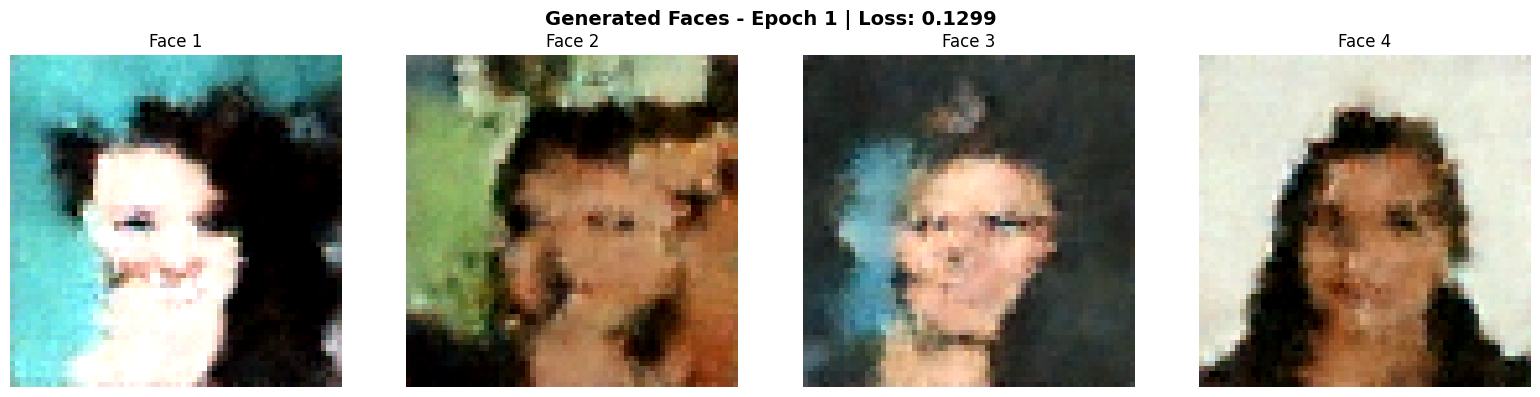

    Epoch time: 441.3s | ETA: 2.3 hours | Loss: 0.1299
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 441s 278ms/step - loss: 0.1299
Epoch 2/20
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 0s 230ms/step - loss: 0.0968
 New best model! (epoch 2)
   Loss: 0.096308 (improved by 0.033583)
   Saved to: checkpoints/unet_best.weights.h5
    Epoch time: 364.3s | ETA: 2.0 hours | Loss: 0.0963
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 364s 230ms/step - loss: 0.0963
Epoch 3/20
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 0s 230ms/step - loss: 0.0944
 New best model! (epoch 3)
   Loss: 0.093848 (improved by 0.002460)
   Saved to: checkpoints/unet_best.weights.h5
    Epoch time: 363.6s | ETA: 1.8 hours | Loss: 0.0938
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 364s 230ms/step - loss: 0.0938
Epoch 4/20
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step - loss: 0.0919
 New best model! (epoch 4)
   Loss: 0.091463 (improved by 0.002385)
   Saved to: checkpoints/unet_best.weights.h5
    Epoch time: 362.9s | ETA: 1.7 hours | Loss: 0.0915
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 363s 229

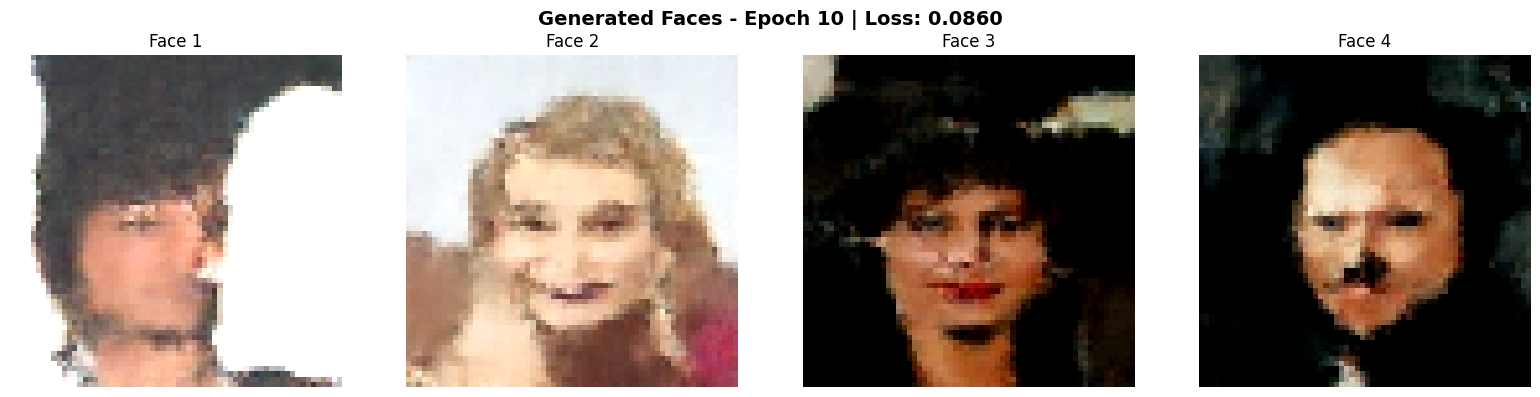

    Epoch time: 373.1s | ETA: 1.0 hours | Loss: 0.0860
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 373s 236ms/step - loss: 0.0860
Epoch 11/20
1578/1582 ━━━━━━━━━━━━━━━━━━━━ 1s 269ms/step - loss: 0.0856 
 New best model! (epoch 11)
   Loss: 0.085523 (improved by 0.000503)
   Saved to: checkpoints/unet_best.weights.h5
    Epoch time: 298.1s | ETA: 55.1 min | Loss: 0.0855
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 298s 229ms/step - loss: 0.0855
Epoch 12/20
1528/1582 ━━━━━━━━━━━━━━━━━━━━ 14s 270ms/step - loss: 0.0856
 New best model! (epoch 12)
   Loss: 0.085280 (improved by 0.000243)
   Saved to: checkpoints/unet_best.weights.h5
    Epoch time: 362.0s | ETA: 48.9 min | Loss: 0.0853
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 362s 229ms/step - loss: 0.0853
Epoch 13/20
1563/1582 ━━━━━━━━━━━━━━━━━━━━ 5s 270ms/step - loss: 0.0851 
 New best model! (epoch 13)
   Loss: 0.084935 (improved by 0.000344)
   Saved to: checkpoints/unet_best.weights.h5
    Epoch time: 362.4s | ETA: 42.8 min | Loss: 0.0849
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 36

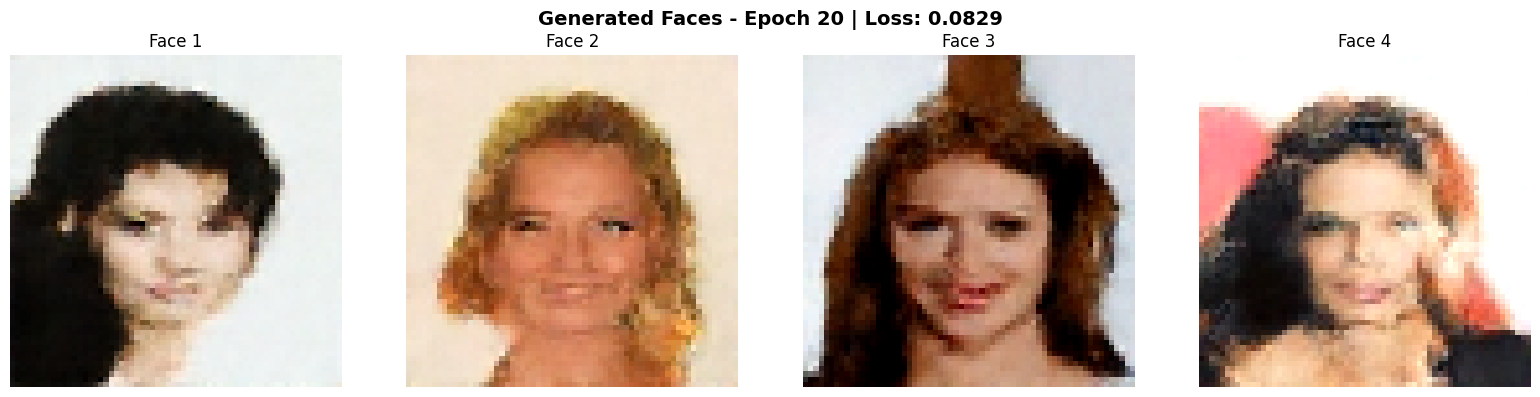

    Epoch time: 310.3s | ETA: 0.0 min | Loss: 0.0829
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 310s 196ms/step - loss: 0.0829

 TRAINING COMPLETED!
Best loss: 0.082920 (epoch 20)
Final loss: 0.082920
Best model saved to: checkpoints/unet_best.weights.h5


In [10]:
import time

EPOCHS = 20

print("=" * 60)
print(" STARTING TRAINING")
print("=" * 60)
print(f"Epochs: {EPOCHS}")
print(f"Image size: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Model: {unet.count_params()/1e6:.1f}M parameters")
print(f"Best model will be saved to: checkpoints/unet_best.weights.h5")
print("=" * 60 + "\n")

# Create callbacks
save_best = SaveBestModelCallback(save_dir='checkpoints')
sample_cb = SampleCallback(size=IMAGE_SIZE, freq=10)
history_cb = TrainingHistoryCallback()

# Train
history = model.fit(
    train_dataset,
    epochs=EPOCHS,
    callbacks=[
        save_best,        # Save only best model
        sample_cb,        # Generate samples every 10 epochs
        history_cb,       # Track progress
        keras.callbacks.TerminateOnNaN()
    ],
    verbose=1
)

print("\n" + "=" * 60)
print(" TRAINING COMPLETED!")
print("=" * 60)
print(f"Best loss: {save_best.best_loss:.6f} (epoch {save_best.best_epoch})")
print(f"Final loss: {history.history['loss'][-1]:.6f}")
print(f"Best model saved to: checkpoints/unet_best.weights.h5")
print("=" * 60)


# Plot Training History

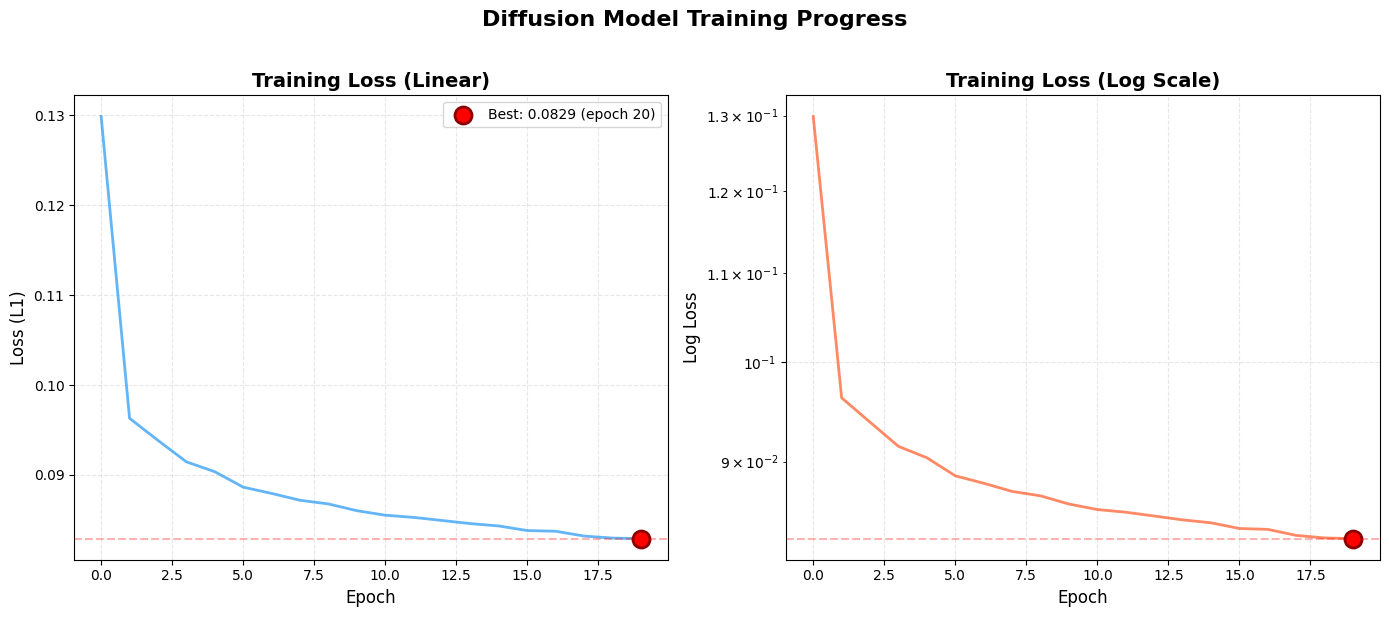


 TRAINING SUMMARY
Total epochs:       20
Initial loss:       0.129892
Final loss:         0.082920
Best loss:          0.082920
Best epoch:         20
Improvement:        36.2%
Model parameters:   6.5M
Training time:      ~7 minutes


In [11]:

plt.figure(figsize=(14, 6))

# Linear scale
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], linewidth=2, color='#2196F3', alpha=0.7)
plt.scatter(save_best.best_epoch - 1, save_best.best_loss, 
           color='red', s=150, zorder=5, edgecolors='darkred', linewidth=2,
           label=f'Best: {save_best.best_loss:.4f} (epoch {save_best.best_epoch})')
plt.axhline(y=save_best.best_loss, color='red', linestyle='--', alpha=0.3)
plt.title('Training Loss (Linear)', fontsize=14, fontweight='bold')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss (L1)', fontsize=12)
plt.grid(True, alpha=0.3, linestyle='--')
plt.legend(fontsize=10)

# Log scale
plt.subplot(1, 2, 2)
plt.semilogy(history.history['loss'], linewidth=2, color='#FF5722', alpha=0.7)
plt.scatter(save_best.best_epoch - 1, save_best.best_loss, 
           color='red', s=150, zorder=5, edgecolors='darkred', linewidth=2)
plt.axhline(y=save_best.best_loss, color='red', linestyle='--', alpha=0.3)
plt.title('Training Loss (Log Scale)', fontsize=14, fontweight='bold')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Log Loss', fontsize=12)
plt.grid(True, alpha=0.3, linestyle='--')

plt.suptitle('Diffusion Model Training Progress', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
plt.show()

# Print summary
print("\n" + "="*60)
print(" TRAINING SUMMARY")
print("="*60)
print(f"Total epochs:       20")
print(f"Initial loss:       {history.history['loss'][0]:.6f}")
print(f"Final loss:         {history.history['loss'][-1]:.6f}")
print(f"Best loss:          {save_best.best_loss:.6f}")
print(f"Best epoch:         {save_best.best_epoch}")
print(f"Improvement:        {(1 - save_best.best_loss/history.history['loss'][0])*100:.1f}%")
print(f"Model parameters:   {unet.count_params()/1e6:.1f}M")
print(f"Training time:      ~{len(history.history['loss']) * 22 / 60:.0f} minutes")
print("="*60)


# Load Best Model & Generate Final Results

 Loading best model...

 Generating final face images...


Sampling: 100%|████████████████████████████████████████████████████████████████████| 1000/1000 [01:24<00:00, 11.86it/s]


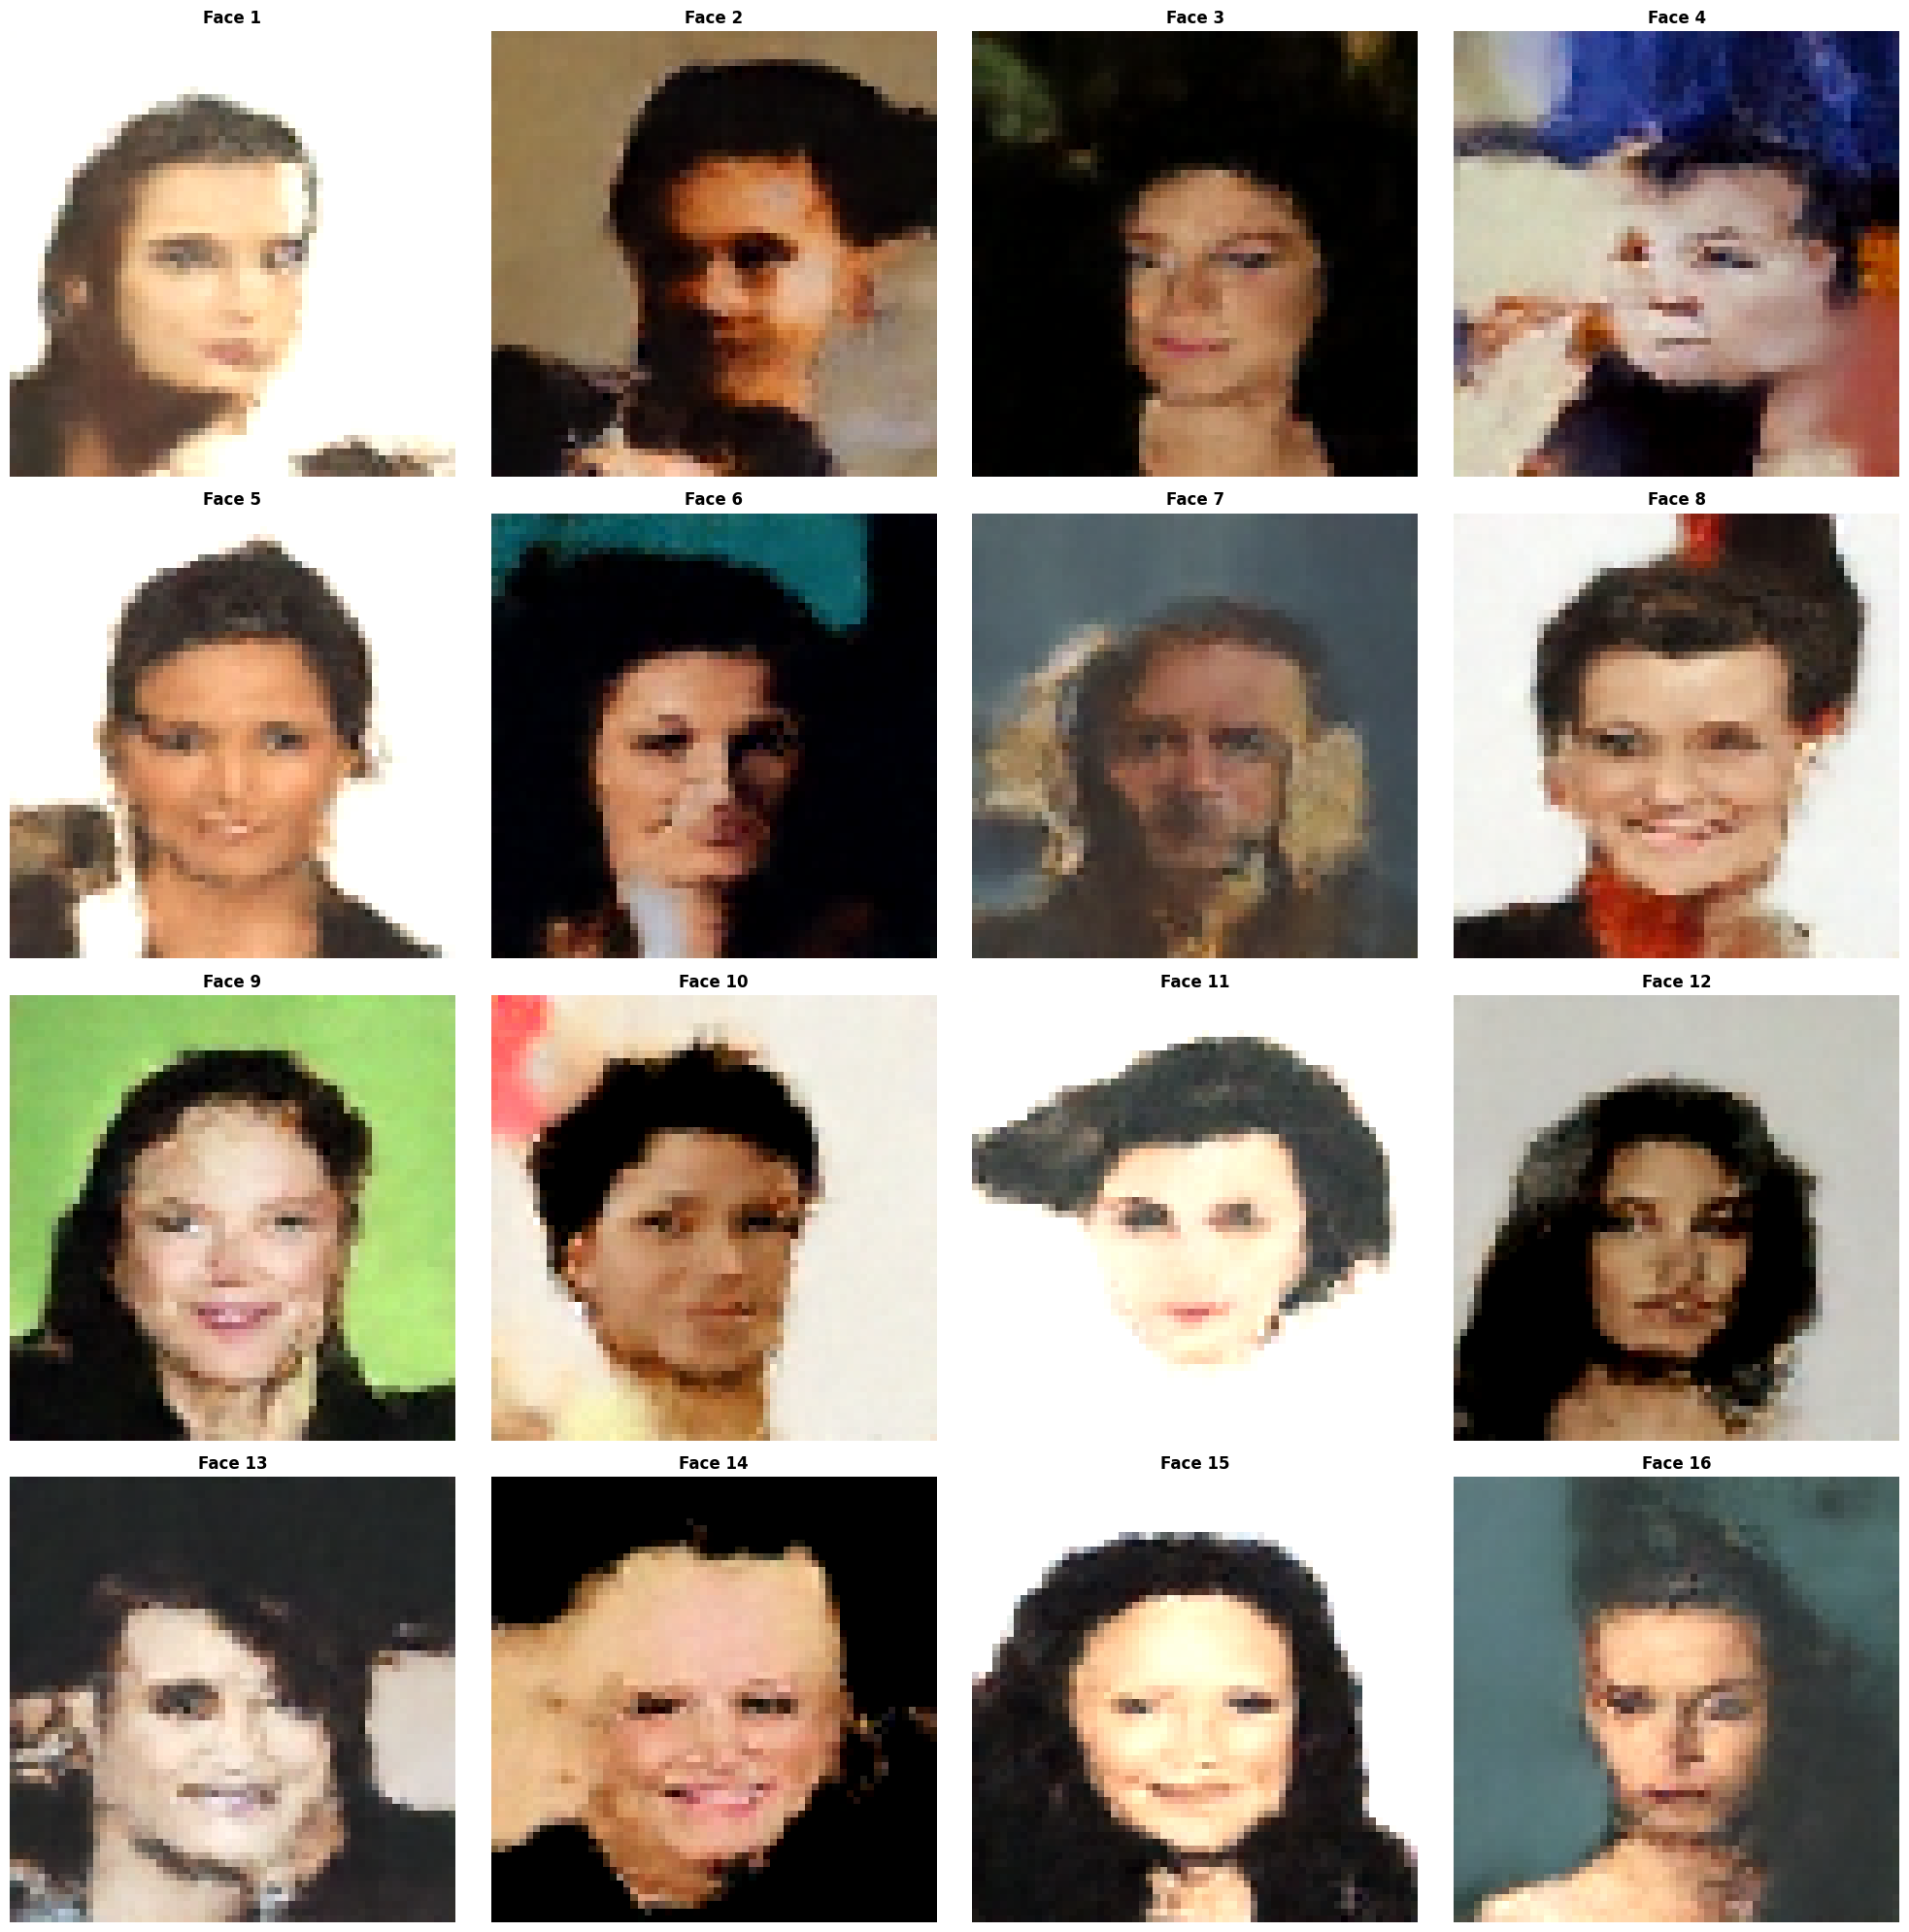

 Saved 16 images to 'results/' folder
 Final grid saved as 'final_generated_faces.png'


In [16]:
print(" Loading best model...")
model.unet.load_weights('checkpoints/unet_best.weights.h5')


print("\n Generating final face images...")
samples = model.sample(IMAGE_SIZE, n=16, show_progress=True)
samples = tf.clip_by_value((samples + 1) / 2, 0, 1).numpy()

# Create beautiful grid
fig, axes = plt.subplots(4, 4, figsize=(20, 20))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i])
    ax.axis('off')
    ax.set_title(f'Face {i+1}', fontsize=12, fontweight='bold')


plt.tight_layout()
plt.savefig('final_generated_faces.png', dpi=200, bbox_inches='tight')
plt.show()

# Save individual images
Path('results').mkdir(exist_ok=True)
for i, img in enumerate(samples):
    pil_img = Image.fromarray((img * 255).astype(np.uint8))
    pil_img.save(f'results/face_{i+1:03d}.png')

print(f" Saved 16 images to 'results/' folder")
print(f" Final grid saved as 'final_generated_faces.png'")